# Predicting 12-month hospitalization after diabetes medication initiation
## Notebook 1: Data preparation and exploratory analysis

This notebook builds an analysis-ready cohort from two synthetic source tables. It demonstrates table merging, patient-specific baseline filtering, long-to-wide reshaping, missingness, skewed variables, scaling, and multicollinearity.

> All records are synthetic and contain no real patient information.

## tl;dr

- The cohort contains **4,000 patients** and the observed 12-month hospitalization rate is approximately **22%**.
- The lab table intentionally contains pre-baseline, baseline, and post-index records. Only baseline records may be used as predictors.
- Baseline labs have at most one result per patient and lab name, so they can be pivoted safely after date filtering.
- Numeric missingness, strongly right-skewed utilization/cost/lab variables, and highly correlated visit counts are deliberate teaching features.


## Goal

By the end of this notebook, students should be able to:

1. Identify the row grain and keys of two related tables.
2. Apply a patient-specific 365-day baseline window.
3. Pivot laboratory data from long to wide format.
4. Examine missingness and distinguish a missing measurement from a measured zero.
5. Recognize variables that may benefit from `log1p` transformation and standardization.
6. Detect intentional multicollinearity before modeling.

## Setup

The notebook expects the source tables in the `data/` folder beside this notebook. The path search also supports launching Jupyter from the project folder.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 20261013
BASELINE_DAYS = 365
TARGET = "hospitalized_12m"

candidate_dirs = [
    Path.cwd() / "data",
    Path.cwd(),
    Path.cwd() / "github" / "data",
    Path.cwd().parent / "data",
]
DATA_DIR = next(
    (path for path in candidate_dirs if (path / "patients.csv").exists() and (path / "labs.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find data/patients.csv and data/labs.csv from the current working directory.")

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {
    "blue": "#2563EB",
    "gold": "#D4A72C",
    "orange": "#E76F51",
    "olive": "#6B7D3A",
    "charcoal": "#30343B",
    "light_blue": "#AFCBFF",
}
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print(f"Data folder: {DATA_DIR.resolve()}")

Data folder: /Users/kchen14@amgen.com/Documents/05_Presentation/DS_in_Epi_UCLA_lecture/github/data


## Step 1: Load the two source tables

In [2]:
patients = pd.read_csv(DATA_DIR / "patients.csv", parse_dates=["index_date"])
labs = pd.read_csv(DATA_DIR / "labs.csv", parse_dates=["lab_date"])

source_summary = pd.DataFrame({
    "table": ["patients", "labs"],
    "rows": [len(patients), len(labs)],
    "columns": [patients.shape[1], labs.shape[1]],
    "row_grain": ["one row per patient", "one row per laboratory result"],
})
display(source_summary)
display(patients.head(3))
display(labs.head(3))

,table,rows,columns,row_grain
0,patients,4000,28,one row per patient
1,labs,41814,5,one row per laboratory result


,patient_id,index_date,index_medication_class,age_at_index,sex,race_ethnicity,insurance_type,smoking_status,diabetes_duration_years,bmi_baseline,...,total_healthcare_cost_baseline,hypertension_baseline,hyperlipidemia_baseline,chronic_kidney_disease_baseline,cardiovascular_disease_baseline,heart_failure_baseline,diabetes_complication_baseline,depression_baseline,charlson_comorbidity_index,hospitalized_12m
0,P000001,2022-02-26,SGLT2 inhibitor,75,Male,Asian,Commercial,Never,4.0,47.0,...,8653,1,0,0,0,0,0,0,2,0
1,P000002,2022-10-11,Insulin,63,Female,Black,Commercial,Former,15.0,NaN,...,3148,1,1,0,0,0,0,0,1,0
2,P000003,2022-08-26,Metformin,79,Male,White,Medicare,Never,10.5,34.6,...,10595,1,0,0,0,0,0,0,2,0


,patient_id,lab_date,lab_name,lab_value,lab_unit
0,P000001,2020-04-08,ldl_cholesterol,99.00,mg/dL
1,P000001,2020-05-09,creatinine,0.65,mg/dL
2,P000001,2020-10-31,alt,11.00,U/L


### Validate keys and table relationships

`patient_id` is the primary key in `patients.csv` and a foreign key in `labs.csv`. These checks should be performed before merging because duplicate patient rows or unmatched lab records could change the analytic population.

In [3]:
assert patients["patient_id"].notna().all(), "Patient IDs must not be missing."
assert patients["patient_id"].is_unique, "patients.csv must contain one row per patient."

unmatched_lab_ids = set(labs["patient_id"]) - set(patients["patient_id"])
assert not unmatched_lab_ids, f"Unmatched lab patient IDs found: {len(unmatched_lab_ids)}"

print(f"Unique patients: {patients['patient_id'].nunique():,}")
print(f"Lab rows with a valid patient foreign key: {len(labs):,}")
print("Primary-key and foreign-key checks passed.")

Unique patients: 4,000
Lab rows with a valid patient foreign key: 41,814
Primary-key and foreign-key checks passed.


## Step 2: Apply the patient-specific baseline window

The baseline period is the 365 days before medication initiation, excluding the index date:

\[
[	ext{index date} - 365	ext{ days},\; 	ext{index date})
\]

A fixed calendar cutoff would be incorrect because every patient has a different index date.

In [4]:
labs_with_index = labs.merge(
    patients[["patient_id", "index_date"]],
    on="patient_id",
    how="left",
    validate="many_to_one",
)
labs_with_index["baseline_start"] = labs_with_index["index_date"] - pd.Timedelta(days=BASELINE_DAYS)

labs_with_index["lab_period"] = np.select(
    [
        labs_with_index["lab_date"] < labs_with_index["baseline_start"],
        (labs_with_index["lab_date"] >= labs_with_index["baseline_start"])
        & (labs_with_index["lab_date"] < labs_with_index["index_date"]),
        labs_with_index["lab_date"] >= labs_with_index["index_date"],
    ],
    ["pre-baseline", "baseline", "post-index"],
    default="unexpected",
)

period_counts = (
    labs_with_index["lab_period"]
    .value_counts()
    .reindex(["pre-baseline", "baseline", "post-index"], fill_value=0)
)
display(period_counts.rename("lab_rows").to_frame())

,lab_rows
lab_period,
pre-baseline,5790
baseline,28456
post-index,7568


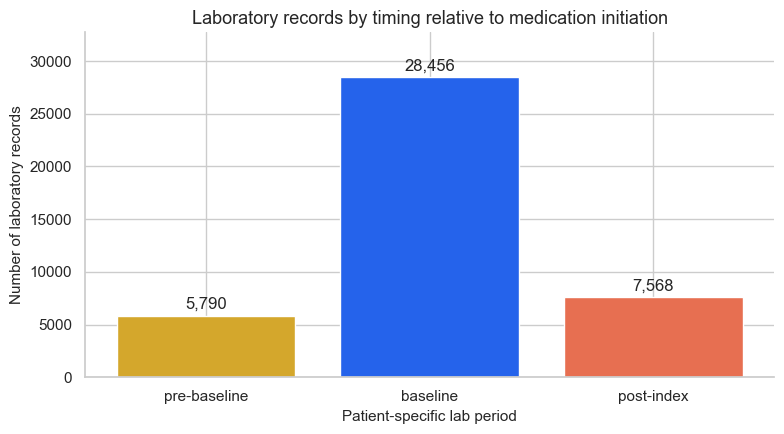

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(period_counts.index, period_counts.values, color=[COLORS["gold"], COLORS["blue"], COLORS["orange"]])
ax.set_title("Laboratory records by timing relative to medication initiation")
ax.set_xlabel("Patient-specific lab period")
ax.set_ylabel("Number of laboratory records")
ax.set_ylim(0, period_counts.max() * 1.15)
ax.bar_label(bars, labels=[f"{value:,}" for value in period_counts.values], padding=3)
plt.tight_layout()
plt.show()

**Interpretation:** Pre-baseline and post-index records are intentionally present. Using them would violate the feature definition and post-index records could introduce outcome leakage.

### Keep baseline labs and verify uniqueness

In [6]:
baseline_labs = labs_with_index.loc[
    labs_with_index["lab_period"].eq("baseline"),
    ["patient_id", "lab_date", "lab_name", "lab_value", "lab_unit"],
].copy()

duplicate_baseline_rows = baseline_labs.duplicated(["patient_id", "lab_name"], keep=False)
assert not duplicate_baseline_rows.any(), "Expected at most one baseline result per patient and lab name."

print(f"Baseline lab rows retained: {len(baseline_labs):,}")
print("No duplicate patient-lab combinations were found within baseline.")

Baseline lab rows retained: 28,456
No duplicate patient-lab combinations were found within baseline.


## Step 3: Pivot baseline labs and merge the analysis table

In [7]:
baseline_labs_wide = (
    baseline_labs
    .pivot(index="patient_id", columns="lab_name", values="lab_value")
    .reset_index()
    .rename_axis(columns=None)
)

analysis_data = patients.merge(
    baseline_labs_wide,
    on="patient_id",
    how="left",
    validate="one_to_one",
)

assert len(analysis_data) == len(patients), "The left join must preserve every patient."
assert analysis_data["patient_id"].is_unique

print(f"Analysis table shape: {analysis_data.shape[0]:,} rows × {analysis_data.shape[1]} columns")
display(analysis_data.head(3))

Analysis table shape: 4,000 rows × 36 columns


,patient_id,index_date,index_medication_class,age_at_index,sex,race_ethnicity,insurance_type,smoking_status,diabetes_duration_years,bmi_baseline,...,charlson_comorbidity_index,hospitalized_12m,alt,creatinine,egfr,glucose,hba1c,hdl_cholesterol,ldl_cholesterol,triglycerides
0,P000001,2022-02-26,SGLT2 inhibitor,75,Male,Asian,Commercial,Never,4.0,47.0,...,2,0,13.0,0.68,84.0,NaN,8.2,36.0,110.0,93.0
1,P000002,2022-10-11,Insulin,63,Female,Black,Commercial,Former,15.0,NaN,...,1,0,NaN,0.99,90.0,275.0,10.9,67.0,155.0,NaN
2,P000003,2022-08-26,Metformin,79,Male,White,Medicare,Never,10.5,34.6,...,2,0,45.0,0.64,79.0,173.0,8.3,53.0,132.0,65.0


## Step 4: Describe the cohort and outcome

,value
Patients,4000.0
Mean age,58.8
Female (%),50.9
Prior hospitalization (%),19.3
Hospitalized within 12 months (%),22.4


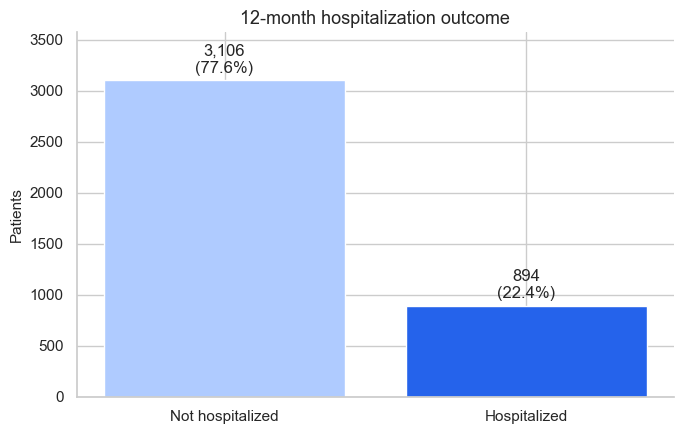

In [8]:
cohort_summary = pd.Series({
    "Patients": len(analysis_data),
    "Mean age": analysis_data["age_at_index"].mean(),
    "Female (%)": 100 * analysis_data["sex"].eq("Female").mean(),
    "Prior hospitalization (%)": 100 * analysis_data["prior_hospitalization_baseline"].mean(),
    "Hospitalized within 12 months (%)": 100 * analysis_data[TARGET].mean(),
}).to_frame("value")
display(cohort_summary.style.format({"value": "{:.1f}"}))

outcome_counts = analysis_data[TARGET].value_counts().sort_index()
outcome_labels = ["Not hospitalized", "Hospitalized"]
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(outcome_labels, outcome_counts.values, color=[COLORS["light_blue"], COLORS["blue"]])
ax.set_title("12-month hospitalization outcome")
ax.set_ylabel("Patients")
ax.set_ylim(0, outcome_counts.max() * 1.15)
ax.bar_label(
    bars,
    labels=[f"{count:,}\n({count / len(analysis_data):.1%})" for count in outcome_counts.values],
    padding=3,
)
plt.tight_layout()
plt.show()

## Step 5: Examine missing data

Blank patient-level values and absent baseline lab rows become missing values in the analysis table. A missing value means “not observed,” not zero. Imputation must later be fitted using training data only.

,missing_percent
alt,16.0%
triglycerides,13.8%
hdl_cholesterol,13.7%
ldl_cholesterol,13.3%
bmi_baseline,10.9%
egfr,10.2%
creatinine,9.6%
systolic_bp_baseline,9.2%
diastolic_bp_baseline,9.2%
diabetes_duration_years,8.0%


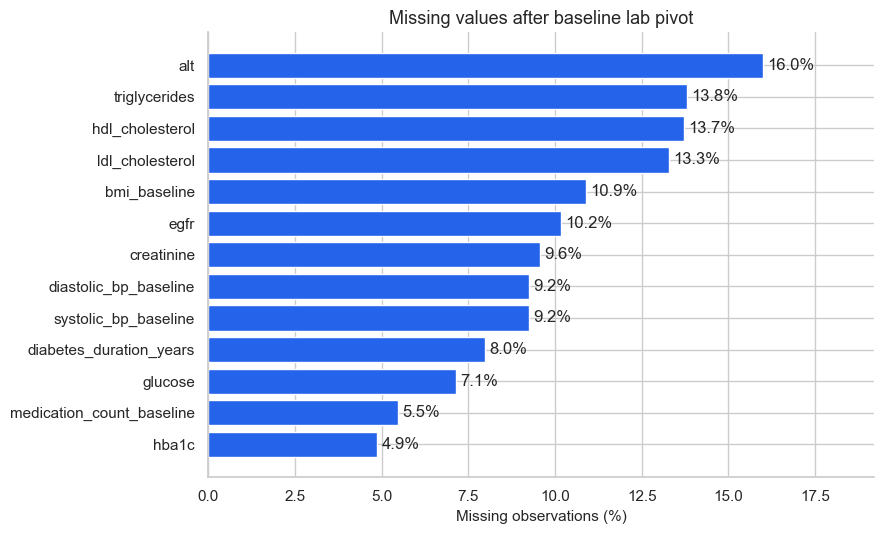

In [9]:
missing_summary = (
    analysis_data.isna().mean()
    .mul(100)
    .rename("missing_percent")
    .loc[lambda values: values > 0]
    .sort_values(ascending=False)
    .to_frame()
)
display(missing_summary.style.format({"missing_percent": "{:.1f}%"}))

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_missing = missing_summary.sort_values("missing_percent")
bars = ax.barh(plot_missing.index, plot_missing["missing_percent"], color=COLORS["blue"])
ax.set_title("Missing values after baseline lab pivot")
ax.set_xlabel("Missing observations (%)")
ax.set_ylabel("")
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in plot_missing["missing_percent"]], padding=3)
ax.set_xlim(0, plot_missing["missing_percent"].max() * 1.2)
plt.tight_layout()
plt.show()

## Step 6: Demonstrate right skew and log transformation

,variable,raw_skewness,log1p_skewness
0,total_healthcare_cost_baseline,13.12,0.02
1,triglycerides,2.89,0.22


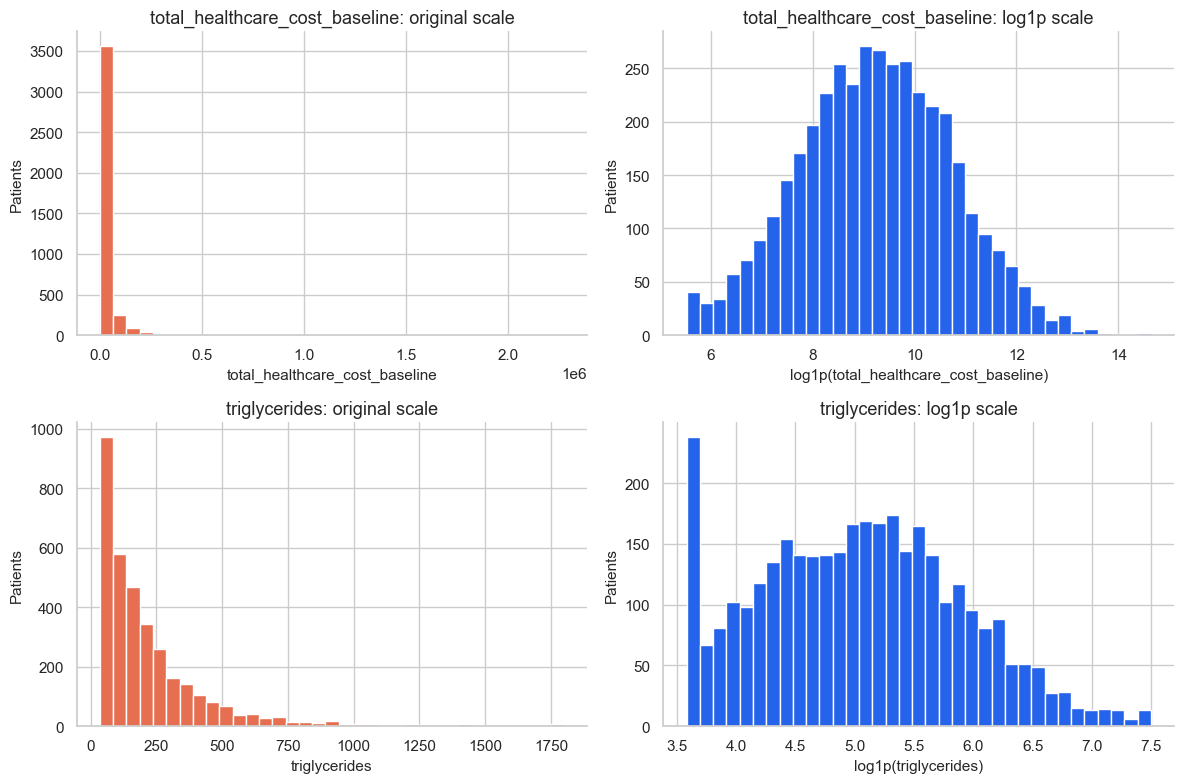

In [10]:
skew_examples = ["total_healthcare_cost_baseline", "triglycerides"]
skew_table = pd.DataFrame({
    "variable": skew_examples,
    "raw_skewness": [analysis_data[column].skew() for column in skew_examples],
    "log1p_skewness": [np.log1p(analysis_data[column]).skew() for column in skew_examples],
})
display(skew_table.style.format({"raw_skewness": "{:.2f}", "log1p_skewness": "{:.2f}"}))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row_index, column in enumerate(skew_examples):
    raw = analysis_data[column].dropna()
    transformed = np.log1p(raw)
    axes[row_index, 0].hist(raw, bins=35, color=COLORS["orange"], edgecolor="white")
    axes[row_index, 0].set_title(f"{column}: original scale")
    axes[row_index, 0].set_xlabel(column)
    axes[row_index, 0].set_ylabel("Patients")
    axes[row_index, 1].hist(transformed, bins=35, color=COLORS["blue"], edgecolor="white")
    axes[row_index, 1].set_title(f"{column}: log1p scale")
    axes[row_index, 1].set_xlabel(f"log1p({column})")
    axes[row_index, 1].set_ylabel("Patients")
plt.tight_layout()
plt.show()

**Interpretation:** `log1p(x)` is appropriate for nonnegative skewed variables because it is defined when `x = 0`. The transformation compresses extreme values and can help a linear model represent diminishing returns.

## Step 7: Demonstrate scaling without leaking test information

In [11]:
scaling_columns = [
    "age_at_index",
    "bmi_baseline",
    "systolic_bp_baseline",
    "hba1c",
    "glucose",
    "egfr",
]

training_rows, test_rows = train_test_split(
    analysis_data.index,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=analysis_data[TARGET],
)
scaling_demo_train = analysis_data.loc[training_rows, scaling_columns]
scaling_demo_test = analysis_data.loc[test_rows, scaling_columns]

training_medians = scaling_demo_train.median()
scaler = StandardScaler()
scaled_train = scaler.fit_transform(scaling_demo_train.fillna(training_medians))
scaled_test = scaler.transform(scaling_demo_test.fillna(training_medians))

scaling_summary = pd.DataFrame({
    "training_mean_before": scaling_demo_train.mean(),
    "training_sd_before": scaling_demo_train.std(),
    "training_mean_after": scaled_train.mean(axis=0),
    "training_sd_after": scaled_train.std(axis=0),
    "test_mean_after_using_training_parameters": scaled_test.mean(axis=0),
})
display(scaling_summary.style.format("{:.2f}"))

,training_mean_before,training_sd_before,training_mean_after,training_sd_after,test_mean_after_using_training_parameters
age_at_index,58.85,12.30,-0.00,1.00,-0.03
bmi_baseline,30.68,5.73,-0.00,1.00,-0.00
systolic_bp_baseline,127.79,13.91,-0.00,1.00,-0.10
hba1c,7.76,1.16,0.00,1.00,0.04
glucose,193.83,33.65,-0.00,1.00,0.03
egfr,90.47,16.27,0.00,1.00,-0.01


**Interpretation:** The imputation values, means, and standard deviations were learned from the training rows and then applied to the test rows. Fitting preprocessing on the entire dataset would leak test information into model development.

## Step 8: Detect multicollinearity

,total_visits_baseline,outpatient_visits_baseline,er_visits_baseline,inpatient_visits_baseline
total_visits_baseline,1.00,0.99,0.16,0.05
outpatient_visits_baseline,0.99,1.00,0.04,-0.01
er_visits_baseline,0.16,0.04,1.00,0.04
inpatient_visits_baseline,0.05,-0.01,0.04,1.00


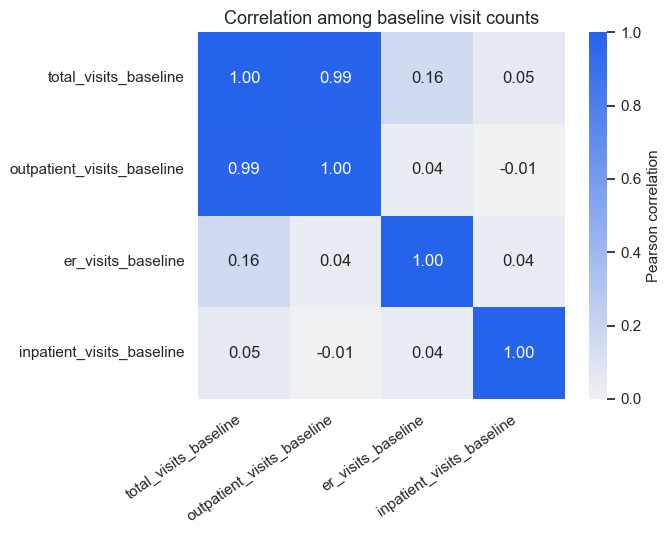

In [12]:
visit_columns = [
    "total_visits_baseline",
    "outpatient_visits_baseline",
    "er_visits_baseline",
    "inpatient_visits_baseline",
]
visit_correlations = analysis_data[visit_columns].corr()

assert (
    analysis_data["total_visits_baseline"]
    == analysis_data["outpatient_visits_baseline"]
    + analysis_data["er_visits_baseline"]
    + analysis_data["inpatient_visits_baseline"]
).all()

display(visit_correlations.style.format("{:.2f}"))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    visit_correlations,
    annot=True,
    fmt=".2f",
    cmap=sns.light_palette(COLORS["blue"], as_cmap=True),
    vmin=0,
    vmax=1,
    square=True,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Correlation among baseline visit counts")
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Interpretation:** `total_visits_baseline` is exactly the sum of the three component counts. A logistic-regression design matrix should retain the total or the components, but not all four. A tree model can still predict with correlated variables, although their feature-importance values may become unstable or split across variables.

## Checks

In [13]:
checks = pd.Series({
    "Patient primary key is unique": patients["patient_id"].is_unique,
    "All lab foreign keys match a patient": len(unmatched_lab_ids) == 0,
    "Baseline boundary is applied per patient": labs_with_index["lab_period"].ne("unexpected").all(),
    "At most one baseline result per patient and lab": not duplicate_baseline_rows.any(),
    "Patient count preserved after merge": len(analysis_data) == len(patients),
    "Outcome contains both classes": analysis_data[TARGET].nunique() == 2,
    "Visit total reconciles to components": (
        analysis_data["total_visits_baseline"]
        == analysis_data["outpatient_visits_baseline"]
        + analysis_data["er_visits_baseline"]
        + analysis_data["inpatient_visits_baseline"]
    ).all(),
}, name="passed")
display(checks.to_frame())
assert checks.all(), "One or more data checks failed."

,passed
Patient primary key is unique,True
All lab foreign keys match a patient,True
Baseline boundary is applied per patient,True
At most one baseline result per patient and lab,True
Patient count preserved after merge,True
Outcome contains both classes,True
Visit total reconciles to components,True


## Takeaways and next steps

- Baseline filtering must occur before pivoting laboratory data.
- Missing baseline labs should remain missing until a training-only imputation step.
- Cost, triglycerides, ALT, and utilization counts are useful log-transformation candidates.
- Continuous variables are on very different scales, which matters for regularized logistic regression.
- Visit totals and their components create intentional multicollinearity.

Continue to **Notebook 2** to train and evaluate minimally processed logistic regression, prepared logistic regression, raw-feature XGBoost, and a prepared-feature XGBoost control.